# 03 — CHT forest ecohydrology: monthly satellite-data pilot and quality audit

**Rangamati, Bandarban, Khagrachhari · local Jupyter · Google Earth Engine · 2020 pilot**

**Research question (working):** How do seasonal precipitation, forest canopy greenness and modeled evapotranspiration vary across CHT districts? Can we derive a consistent, quality-controlled monthly panel before extending to 2017–2022?

Notebook 02C confirmed that quality-approved SMAP observations are absent from most forest-classified sample locations. **SMAP is therefore not used as a CHT-wide training target in this notebook.** We analyze satellite- and model-derived ecohydrological *indicators*, not independently validated soil moisture or forest hydrological fluxes.

**This notebook is an extraction and quality pilot, not a scientific results paper or a machine-learning exercise.** It creates 12 × 3 = 36 monthly-district records for 2020 (default) and local CSV/PNG files. It does not launch GEE exports, overwrite the shapefile, authenticate automatically, upload to GitHub or train a model.

Run cells in order using your project Python kernel. For a faster three-month test change `PILOT_MONTH_NUMBERS` in the configuration cell under Section 2 to `[1, 7, 11]`.


## 1. Variables and interpretation

| Indicator | Product | Role | Important qualification |
|---|---|---|---|
| Monthly rainfall (mm) | [CHIRPS v3 Daily Reanalysis](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_DAILY_RNL) | Water supply | Includes satellite and station data; ERA5 partitions rainfall from pentads into individual days. Monthly accumulation is the main use here. |
| Forest EVI | [MODIS MOD13Q1 v6.1](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD13Q1) | Canopy greenness | 16-day composites, QA `SummaryQA==0`, scaled by 0.0001. Monthly median of composites *starting* that month is approximate, not a daily vegetation observation. |
| Monthly forest ET (mm) | [MODIS MOD16A2GF v6.1](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD16A2GF) | Model-derived water flux | Gap-filled Penman–Monteith product, not directly measured ET. 8-day totals are apportioned by overlap with the calendar month, including the short last composite of each year. |
| Forest classification | [MODIS MCD12Q1 v6.1](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MCD12Q1) | Forest mask | Static 2021 IGBP classes 1–5, approximate 500 m classification. Not field-verified forest fraction or a land-cover change dataset. |

**Spatial interpretation:** CHIRPS rainfall is averaged across the **whole district at its coarse native scale**. EVI and ET are averaged only over pixels classified as forest by MODIS 2021. These are district-scale indicators from sources of different native resolutions. We do *not* resample rainfall into fictitious 250 m measurements.

**Temporal interpretation:** EVI is an approximate monthly greenness proxy. ET is apportioned to exact calendar-month boundaries from 8-day composite totals. We analyze monthly, not daily, ecological relationships. No individual station or field data are available yet.


## 2. Load local boundary and configuration

The three features remain separate. A simplified *in-memory* copy reduces Earth Engine geometry size; the original `.shp` is not changed. The Google Cloud project is loaded from `configs/study_config.json`.


In [1]:
from pathlib import Path
from shapely.geometry import mapping
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ee

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'configs' / 'study_config.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Launch JupyterLab from the research root or notebooks folder.')
CONFIG = json.loads((ROOT / 'configs' / 'study_config.json').read_text(encoding='utf-8'))
NAME = CONFIG['district_name_field']
DISTRICTS = gpd.read_file(ROOT / CONFIG['boundary_relative_path'])
assert DISTRICTS.crs is not None and DISTRICTS.geometry.is_valid.all()
assert set(DISTRICTS[NAME]) == set(CONFIG['expected_districts'])
DISTRICTS = DISTRICTS.to_crs('EPSG:4326')

PILOT_YEAR = 2020
PILOT_MONTH_NUMBERS = list(range(1, 13))  # Faster first test: [1, 7, 11]
FOREST_MAP_YEAR = 2021
EVI_STRICT_QA = 0
MIN_EVI_FOREST_COVERAGE = 0.25  # Audit threshold; not an accuracy guarantee
MIN_ET_PIXEL_DAY_COVERAGE = 0.90  # Mask ET cells lacking sufficient composite-day coverage
SAVE_RESULTS = True

assert PILOT_YEAR >= 2001 and all(1 <= m <= 12 for m in PILOT_MONTH_NUMBERS)
assert len(PILOT_MONTH_NUMBERS) == len(set(PILOT_MONTH_NUMBERS))
print('Project root:', ROOT)
print('GEE Cloud project:', CONFIG['gee_project_id'])
print('Districts:', ', '.join(sorted(DISTRICTS[NAME])))
print('Pilot months:', [f'{PILOT_YEAR}-{m:02d}' for m in PILOT_MONTH_NUMBERS])


Project root: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml
GEE Cloud project: axial-paratext-491911-b6
Districts: Bandarban, Khagrachhari, Rangamati
Pilot months: ['2020-01', '2020-02', '2020-03', '2020-04', '2020-05', '2020-06', '2020-07', '2020-08', '2020-09', '2020-10', '2020-11', '2020-12']


## 3. Connect and verify the dataset inventory

Earth Engine must be initialized **before** constructing EE geometries. This step makes read-only requests to confirm each dataset and required band exists for the pilot period. If a dataset is absent, stop rather than silently substitute another collection or zero-fill.


In [2]:
ee.Initialize(project=CONFIG['gee_project_id'])
GEE_DISTRICTS = ee.FeatureCollection([
    ee.Feature(ee.Geometry(mapping(row.geometry.simplify(0.001, preserve_topology=True))),
               {'district': str(row[NAME])})
    for _, row in DISTRICTS.iterrows()
])

IDS = {
    'CHIRPS_v3_RNL': 'UCSB-CHC/CHIRPS/V3/DAILY_RNL',
    'MOD13Q1_v061': 'MODIS/061/MOD13Q1',
    'MOD16A2GF_v061': 'MODIS/061/MOD16A2GF',
    'MCD12Q1_v061': 'MODIS/061/MCD12Q1',
}
RAIN = ee.ImageCollection(IDS['CHIRPS_v3_RNL'])
VEG = ee.ImageCollection(IDS['MOD13Q1_v061'])
ET = ee.ImageCollection(IDS['MOD16A2GF_v061'])
LC = ee.ImageCollection(IDS['MCD12Q1_v061'])

pilot_start, pilot_end = f'{PILOT_YEAR}-01-01', f'{PILOT_YEAR + 1}-01-01'
sources = [(RAIN, 'CHIRPS_v3_RNL', ['precipitation']),
           (VEG, 'MOD13Q1_v061', ['EVI', 'SummaryQA']),
           (ET, 'MOD16A2GF_v061', ['ET', 'ET_QC'])]
inventory = []
for collection, name, required_bands in sources:
    subset = collection.filterDate(pilot_start, pilot_end)
    n = subset.size().getInfo()
    if n == 0:
        raise RuntimeError(f'{name}: no imagery in pilot year {PILOT_YEAR}.')
    bands = set(ee.Image(subset.first()).bandNames().getInfo())
    if not set(required_bands).issubset(bands):
        raise RuntimeError(f'{name}: missing required bands {set(required_bands) - bands}.')
    inventory.append({'dataset': name, 'year': PILOT_YEAR, 'images': n})

lc_2021 = LC.filterDate(f'{FOREST_MAP_YEAR}-01-01', f'{FOREST_MAP_YEAR + 1}-01-01')
assert lc_2021.size().getInfo() > 0, 'Forest land-cover reference not available.'
assert 'LC_Type1' in ee.Image(lc_2021.first()).bandNames().getInfo()
IGBP = ee.Image(lc_2021.first()).select('LC_Type1')
FOREST = IGBP.gte(1).And(IGBP.lte(5)).rename('forest_modis_2021')

display(pd.DataFrame(inventory))
print('MODIS land-cover year:', FOREST_MAP_YEAR)


,dataset,year,images
0,CHIRPS_v3_RNL,2020,366
1,MOD13Q1_v061,2020,23
2,MOD16A2GF_v061,2020,46


MODIS land-cover year: 2021


## 4. Define QA masks and temporal weighting

MODIS `SummaryQA == 0` is the strict good-quality category. We mask implausible raw EVI values before multiplying by 0.0001. We also calculate the proportion of MODIS-classified forest pixels with at least one valid EVI observation in the monthly composite.

For ET, each valid 8-day amount is allocated to calendar months by the number of contributing days. December's last MOD16 composite is 5 or 6 days, not 8. ET values with fewer than 90% of the month represented are masked, and the coverage is retained as a quality indicator. `ET_QC` bit 0 indicates whether the main algorithm was used; its fractional temporal support is recorded separately rather than silently treating all gap-filled values as field observations.


In [5]:
def table_from_regions(image, scale_m):
    reduced = ee.Image(image).reduceRegions(
        collection=GEE_DISTRICTS,
        reducer=ee.Reducer.mean().forEachBand(ee.Image(image)),
        scale=scale_m, tileScale=4)
    properties_only = reduced.map(
        lambda f: ee.Feature(None, ee.Feature(f).toDictionary()))
    records = [f['properties'] for f in properties_only.getInfo()['features']]
    return pd.DataFrame(records)


def quality_evi(image):
    img = ee.Image(image)
    raw = img.select('EVI')
    good = img.select('SummaryQA').eq(EVI_STRICT_QA)
    plausible = raw.gte(-2000).And(raw.lte(10000))
    return raw.multiply(0.0001).updateMask(good.And(plausible)).rename('evi')


def weighted_et_composite(image, month_start, month_end):
    """Apportion an 8-day MOD16 amount to its overlap with a calendar month."""
    image = ee.Image(image)
    start = image.date()
    year_end = ee.Date.fromYMD(ee.Number(start.get('year')).add(1), 1, 1)
    period_end = ee.Date(ee.Number(start.advance(8, 'day').millis())
                         .min(year_end.millis()))
    overlap_start = ee.Date(ee.Number(start.millis()).max(month_start.millis()))
    overlap_end = ee.Date(ee.Number(period_end.millis()).min(month_end.millis()))
    days = ee.Number(overlap_end.difference(overlap_start, 'day')).max(0)
    period_length = ee.Number(period_end.difference(start, 'day'))

    raw_et = image.select('ET')
    valid = raw_et.gte(0).And(raw_et.lt(32700))
    main_algorithm = image.select('ET_QC').bitwiseAnd(1).eq(0)
    mm = raw_et.multiply(0.1).multiply(days.divide(period_length)).updateMask(valid)
    # Keep the MODIS ET pixel grid for all three bands; a bare constant image
    # otherwise starts in Earth Engine's default one-degree projection.
    valid_days = raw_et.multiply(0).add(days).updateMask(valid)
    main_days = raw_et.multiply(0).add(days).updateMask(valid.And(main_algorithm))
    return ee.Image.cat([mm.rename('et_weighted_mm'),
                         valid_days.rename('et_valid_days'),
                         main_days.rename('et_main_algorithm_days')]).toFloat()


forest_summary = table_from_regions(FOREST.toFloat().rename('forest_fraction_2021'), 500)
assert {'district', 'forest_fraction_2021'}.issubset(forest_summary.columns)
print('Static forest fractions (MODIS 2021; diagnostic only):')
display(forest_summary[['district', 'forest_fraction_2021']].round(3))


Static forest fractions (MODIS 2021; diagnostic only):


,district,forest_fraction_2021
0,Bandarban,0.337
1,Khagrachhari,0.231
2,Rangamati,0.416


In [6]:
# Diagnose Notebook 03, Cell 4

print("1. Number of districts in GEE:")
print(GEE_DISTRICTS.size().getInfo())

print("\n2. Forest image band:")
print(FOREST.bandNames().getInfo())

print("\n3. Returned DataFrame columns:")
print(forest_summary.columns.tolist())

print("\n4. Forest summary:")
display(forest_summary)

print("\n5. Raw Earth Engine reduction:")
raw_summary = (
    FOREST.toFloat()
    .rename('forest_fraction_2021')
    .reduceRegions(
        collection=GEE_DISTRICTS,
        reducer=ee.Reducer.mean(),
        scale=500,
        tileScale=4
    )
)

print(ee.Feature(raw_summary.first()).toDictionary().getInfo())

1. Number of districts in GEE:
3

2. Forest image band:
['forest_modis_2021']

3. Returned DataFrame columns:
['district', 'forest_fraction_2021']

4. Forest summary:


,district,forest_fraction_2021
0,Bandarban,0.337058
1,Khagrachhari,0.231358
2,Rangamati,0.415639



5. Raw Earth Engine reduction:
{'district': 'Bandarban', 'mean': 0.33705806323557624}


In [7]:
# Diagnose Notebook 03, Cell 4

print("1. Number of districts in GEE:")
print(GEE_DISTRICTS.size().getInfo())

print("\n2. Forest image band:")
print(FOREST.bandNames().getInfo())

print("\n3. Returned DataFrame columns:")
print(forest_summary.columns.tolist())

print("\n4. Forest summary:")
display(forest_summary)

print("\n5. Raw Earth Engine reduction:")
raw_summary = (
    FOREST.toFloat()
    .rename('forest_fraction_2021')
    .reduceRegions(
        collection=GEE_DISTRICTS,
        reducer=ee.Reducer.mean(),
        scale=500,
        tileScale=4
    )
)

print(ee.Feature(raw_summary.first()).toDictionary().getInfo())

1. Number of districts in GEE:
3

2. Forest image band:
['forest_modis_2021']

3. Returned DataFrame columns:
['district', 'forest_fraction_2021']

4. Forest summary:


,district,forest_fraction_2021
0,Bandarban,0.337058
1,Khagrachhari,0.231358
2,Rangamati,0.415639



5. Raw Earth Engine reduction:
{'district': 'Bandarban', 'mean': 0.33705806323557624}


## 5. Run the 2020 monthly pilot

This is the main Earth Engine step. It makes small district-level requests, not full raster downloads. Each month is printed when finished. A monthly CHIRPS series must contain **all calendar days**; otherwise the notebook stops to avoid understating rainfall.

The rainfall columns are district-wide. EVI/ET columns describe the area MODIS **classified as forest in 2021** within each district. They should not be combined into pixel-scale causal interpretations.


In [8]:
monthly_tables = []
month_inventory = []

for month_number in PILOT_MONTH_NUMBERS:
    first = pd.Timestamp(year=PILOT_YEAR, month=month_number, day=1)
    following = first + pd.offsets.MonthBegin(1)
    first_str, following_str = first.strftime('%Y-%m-%d'), following.strftime('%Y-%m-%d')
    start_ee, end_ee = ee.Date(first_str), ee.Date(following_str)
    ndays = int((following - first).days)
    label = first.strftime('%Y-%m')

    rain_collection = RAIN.filterDate(first_str, following_str).select('precipitation')
    count_rain = rain_collection.size().getInfo()
    if count_rain != ndays:
        raise RuntimeError(f'CHIRPS {label}: {count_rain} daily images; expected {ndays}. STOP.')
    rain_mm = rain_collection.sum().rename('rain_mm_district')
    rain_stats = table_from_regions(rain_mm, 5566)

    veg_collection = VEG.filterDate(first_str, following_str)
    count_veg = veg_collection.size().getInfo()
    if count_veg == 0:
        raise RuntimeError(f'MOD13Q1 EVI {label}: no composites.')
    evi = veg_collection.map(quality_evi).median().rename('evi_forest')
    evi_qa_fraction = evi.mask().unmask(0).rename('evi_qa_pixel_support')

    # Include MOD16 composites starting up to eight days before this month.
    et_collection = ET.filterDate(start_ee.advance(-8, 'day'), end_ee)
    count_et = et_collection.size().getInfo()
    if count_et == 0:
        raise RuntimeError(f'MOD16A2GF ET {label}: no overlapping composites.')
    weighted_et = et_collection.map(
        lambda image: weighted_et_composite(image, start_ee, end_ee))
    et_sum = weighted_et.select('et_weighted_mm').sum()
    et_valid_day_fraction = weighted_et.select('et_valid_days').sum().divide(ndays)
    et_main_day_fraction = weighted_et.select('et_main_algorithm_days').sum().divide(ndays)
    et_valid_day_fraction = et_valid_day_fraction.unmask(0).clamp(0, 1)
    et_main_day_fraction = et_main_day_fraction.unmask(0).clamp(0, 1)
    et_month = et_sum.updateMask(
        et_valid_day_fraction.gte(MIN_ET_PIXEL_DAY_COVERAGE)).rename('et_mm_forest')

    forest_indicators = ee.Image.cat([
        evi.updateMask(FOREST).rename('evi_forest'),
        evi_qa_fraction.updateMask(FOREST).rename('evi_qa_pixel_support'),
        et_month.updateMask(FOREST).rename('et_mm_forest'),
        et_valid_day_fraction.updateMask(FOREST).rename('et_day_support'),
        et_main_day_fraction.updateMask(FOREST).rename('et_main_algorithm_day_support'),
    ])
    forest_stats = table_from_regions(forest_indicators, 500)
    row = rain_stats.merge(forest_stats, on='district', validate='one_to_one')
    row = row.merge(forest_summary[['district', 'forest_fraction_2021']],
                    on='district', validate='one_to_one')
    row.insert(0, 'month', label)
    row['month_days'] = ndays
    row['rain_days'] = count_rain
    row['evi_composites_by_start'] = count_veg
    row['et_composites_near_month'] = count_et
    monthly_tables.append(row)
    month_inventory.append({'month': label, 'calendar_days': ndays,
                            'chirps_daily_images': count_rain,
                            'evi_16day_composites': count_veg,
                            'et_8day_composites_considered': count_et})
    print(label, 'finished:', len(row), 'districts')

monthly = pd.concat(monthly_tables, ignore_index=True).sort_values(
    ['district', 'month']).reset_index(drop=True)
inventory_months = pd.DataFrame(month_inventory)
assert len(monthly) == 3 * len(PILOT_MONTH_NUMBERS)
display(monthly.head(12).round(3))


2020-01 finished: 3 districts
2020-02 finished: 3 districts
2020-03 finished: 3 districts
2020-04 finished: 3 districts
2020-05 finished: 3 districts
2020-06 finished: 3 districts
2020-07 finished: 3 districts
2020-08 finished: 3 districts
2020-09 finished: 3 districts
2020-10 finished: 3 districts
2020-11 finished: 3 districts
2020-12 finished: 3 districts


,month,district,rain_mm_district,et_day_support,et_main_algorithm_day_support,et_mm_forest,evi_forest,evi_qa_pixel_support,forest_fraction_2021,month_days,rain_days,evi_composites_by_start,et_composites_near_month
0,2020-01,Bandarban,47.148,1.0,0.995,91.577,0.413,0.778,0.337,31,31,2,5
1,2020-02,Bandarban,10.995,1.0,1.000,89.079,0.393,1.000,0.337,29,29,2,5
2,2020-03,Bandarban,10.058,1.0,1.000,88.148,0.359,0.959,0.337,31,31,2,5
3,2020-04,Bandarban,165.610,1.0,0.946,74.599,0.363,0.980,0.337,30,30,2,5
4,2020-05,Bandarban,219.253,1.0,0.868,108.004,0.415,0.425,0.337,31,31,2,4
5,2020-06,Bandarban,667.010,1.0,0.475,126.674,0.676,0.038,0.337,30,30,2,5
6,2020-07,Bandarban,742.624,1.0,0.337,138.154,0.755,0.211,0.337,31,31,2,5
7,2020-08,Bandarban,714.631,1.0,0.207,137.020,0.738,0.067,0.337,31,31,2,5
8,2020-09,Bandarban,398.104,1.0,0.502,134.373,0.668,0.738,0.337,30,30,2,5
9,2020-10,Bandarban,364.263,1.0,0.804,135.201,0.600,1.000,0.337,31,31,2,5


## 6. Perform an explicit quality audit

The pilot retains missing EVI or ET values as `NaN` in pandas. It **never fills missing EVI with zero**. A column `evi_support_flag` marks months with less than 25% of MODIS-classified forest represented by strict-quality EVI pixels. The threshold is a conservative diagnostic decision, not independent measurement accuracy.

The MOD16A2GF ET product is **already model-based and temporally gap-filled**. The `et_main_algorithm_day_support` field reports how much of the month used the main retrieval algorithm according to `ET_QC` bit 0; even high values do not establish ground accuracy.


In [9]:
required_cols = {'district', 'month', 'rain_mm_district', 'evi_forest',
                 'evi_qa_pixel_support', 'et_mm_forest', 'et_day_support',
                 'et_main_algorithm_day_support', 'forest_fraction_2021'}
assert required_cols.issubset(monthly.columns), (
    f'Missing expected output columns: {required_cols - set(monthly.columns)}')

monthly['evi_support_flag'] = monthly['evi_qa_pixel_support'].apply(
    lambda value: 'low' if pd.isna(value) or value < MIN_EVI_FOREST_COVERAGE else 'ok')
monthly['et_coverage_flag'] = monthly['et_day_support'].apply(
    lambda value: 'low' if pd.isna(value) or value < MIN_ET_PIXEL_DAY_COVERAGE else 'ok')

assert (monthly['rain_mm_district'].dropna() >= 0).all()
assert monthly['evi_qa_pixel_support'].dropna().between(0, 1).all()
assert monthly['et_day_support'].dropna().between(0, 1).all()
assert monthly['et_main_algorithm_day_support'].dropna().between(0, 1).all()
assert monthly['forest_fraction_2021'].dropna().between(0, 1).all()

quality_summary = monthly.groupby('district', as_index=False).agg(
    months=('month', 'size'),
    mean_rain_mm=('rain_mm_district', 'mean'),
    mean_forest_evi=('evi_forest', 'mean'),
    mean_forest_et_mm=('et_mm_forest', 'mean'),
    avg_evi_qa_fraction=('evi_qa_pixel_support', 'mean'),
    avg_et_day_support=('et_day_support', 'mean'),
    low_evi_months=('evi_support_flag', lambda s: int((s == 'low').sum())),
    low_et_months=('et_coverage_flag', lambda s: int((s == 'low').sum())))

print('Quality summary (screening; not final scientific interpretation):')
display(quality_summary.round(3))
print('Monthly warning rows:')
display(monthly[(monthly.evi_support_flag == 'low') |
                (monthly.et_coverage_flag == 'low')][
    ['month', 'district', 'evi_qa_pixel_support', 'et_day_support',
     'evi_support_flag', 'et_coverage_flag']])


Quality summary (screening; not final scientific interpretation):


,district,months,mean_rain_mm,mean_forest_evi,mean_forest_et_mm,avg_evi_qa_fraction,avg_et_day_support,low_evi_months,low_et_months
0,Bandarban,12,286.863,0.538,115.060,0.681,1.000,3,0
1,Khagrachhari,12,243.972,0.526,114.994,0.659,1.000,3,0
2,Rangamati,12,276.204,0.531,110.288,0.740,0.989,3,0


Monthly warning rows:


,month,district,evi_qa_pixel_support,et_day_support,evi_support_flag,et_coverage_flag
5,2020-06,Bandarban,0.037946,1.0000,low,ok
6,2020-07,Bandarban,0.211466,1.0000,low,ok
7,2020-08,Bandarban,0.067313,1.0000,low,ok
17,2020-06,Khagrachhari,0.009682,1.0000,low,ok
18,2020-07,Khagrachhari,0.074521,1.0000,low,ok
19,2020-08,Khagrachhari,0.119620,1.0000,low,ok
29,2020-06,Rangamati,0.138639,0.9886,low,ok
30,2020-07,Rangamati,0.208020,0.9886,low,ok
31,2020-08,Rangamati,0.198347,0.9886,low,ok


## 7. Plot the district-wide pilot without inventing spatial detail

Plots show the three district averages separately. The rainfall, EVI and ET panels have different physical meanings and must not be added together or interpreted causally. Quality support is plotted explicitly because cloud/QA filtering may remove a large part of the monsoon canopy observations.


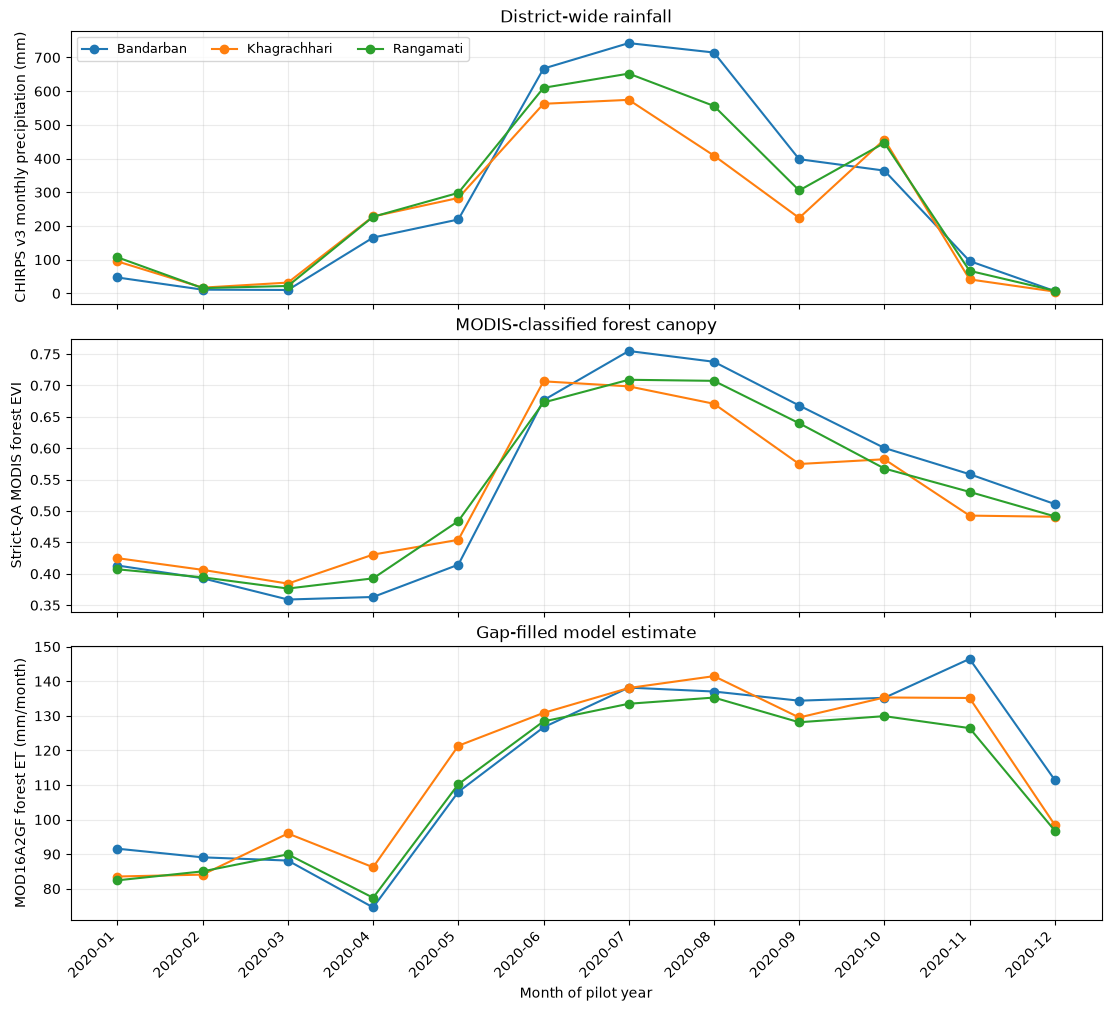

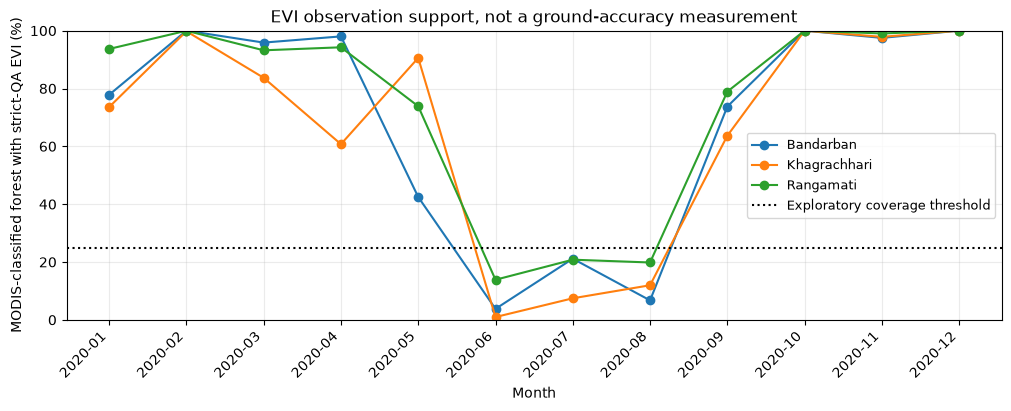

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True, constrained_layout=True)
variables = [
    ('rain_mm_district', 'CHIRPS v3 monthly precipitation (mm)', 'District-wide rainfall'),
    ('evi_forest', 'Strict-QA MODIS forest EVI', 'MODIS-classified forest canopy'),
    ('et_mm_forest', 'MOD16A2GF forest ET (mm/month)', 'Gap-filled model estimate'),
]
for district, frame in monthly.groupby('district'):
    for ax, (key, ylabel, title) in zip(axes, variables):
        ax.plot(frame.month, frame[key], marker='o', label=district)
        ax.set(ylabel=ylabel, title=title)
        ax.grid(alpha=0.25)
axes[0].legend(ncol=3, fontsize=9)
axes[-1].set_xlabel('Month of pilot year')
plt.setp(axes[-1].get_xticklabels(), rotation=45, ha='right')
plt.show()

fig_qa, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for district, frame in monthly.groupby('district'):
    ax.plot(frame.month, 100 * frame.evi_qa_pixel_support,
            marker='o', label=district)
ax.axhline(100 * MIN_EVI_FOREST_COVERAGE, color='black', linestyle=':',
           label='Exploratory coverage threshold')
ax.set(xlabel='Month', ylabel='MODIS-classified forest with strict-QA EVI (%)',
       title='EVI observation support, not a ground-accuracy measurement', ylim=(0, 100))
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()


## 8. Save small local outputs

Nothing is saved to Earth Engine or pushed to GitHub. Set `SAVE_RESULTS=False` in the configuration cell under Section 2 if you want to inspect without saving. **Rerunning with saving enabled replaces the six existing `03_*` pilot output files**, if any. Earlier `00_*`, `01_*`, and `02_*` files are not touched. For reproducibility, the manifest records product IDs, the selected months and QA decisions. CSVs preserve missing values as empty fields.


In [11]:
if SAVE_RESULTS:
    tables = ROOT / 'outputs' / 'tables'
    figures = ROOT / 'outputs' / 'figures'
    tables.mkdir(parents=True, exist_ok=True)
    figures.mkdir(parents=True, exist_ok=True)
    monthly.to_csv(tables / '03_forest_ecohydrology_monthly_pilot.csv', index=False)
    inventory_months.to_csv(tables / '03_monthly_source_inventory.csv', index=False)
    quality_summary.to_csv(tables / '03_district_quality_summary.csv', index=False)
    fig.savefig(figures / '03_rainfall_forest_evi_et_pilot.png', dpi=180, bbox_inches='tight')
    fig_qa.savefig(figures / '03_forest_evi_qa_coverage.png', dpi=180, bbox_inches='tight')

    manifest = {'pilot_year': PILOT_YEAR, 'months': PILOT_MONTH_NUMBERS,
                'cloud_project': CONFIG['gee_project_id'],
                'forest_map_year': FOREST_MAP_YEAR,
                'original_boundary': CONFIG['boundary_relative_path'],
                'ee_products': IDS, 'evi_summary_qa_equal': EVI_STRICT_QA,
                'min_evi_forest_coverage': MIN_EVI_FOREST_COVERAGE,
                'min_et_pixel_day_coverage': MIN_ET_PIXEL_DAY_COVERAGE,
                'temporal_note': 'MOD13Q1 16-day start-date grouping; MOD16 GF ET calendar overlap weighting',
                'limitations': 'No independent ground validation. CHIRPS district-wide; EVI/ET MODIS 2021 forest-classified.'}
    (tables / '03_pilot_method_manifest.json').write_text(
        json.dumps(manifest, indent=2), encoding='utf-8')
    print('Saved 3 CSVs, 1 JSON manifest and 2 PNGs in outputs/.')
else:
    print('SAVE_RESULTS=False; no local outputs saved.')


Saved 3 CSVs, 1 JSON manifest and 2 PNGs in outputs/.


## 9. Stop here and review before the full 2017–2022 analysis

Please share these five files from your PC:

1. `outputs/tables/03_forest_ecohydrology_monthly_pilot.csv`
2. `outputs/tables/03_monthly_source_inventory.csv`
3. `outputs/tables/03_district_quality_summary.csv`
4. `outputs/figures/03_rainfall_forest_evi_et_pilot.png`
5. `outputs/figures/03_forest_evi_qa_coverage.png`

Together we will check whether the rainfall totals, forest EVI and ET appear plausible, where cloud/quality filtering reduces support, and whether the same variable definitions can be extended to all study years. **Do not treat these pilot graphics as final academic conclusions.**

### Methodology decision after this pilot

- If coverage is adequate, expand the *same* fixed products and QA rules to the entire 2017–2022 period and inspect interannual anomalies. Only later consider simple explanatory/statistical models with temporal validation.
- If strict-quality EVI coverage is too low, compare a documented *quality sensitivity* (e.g. careful `DetailedQA` decoding) before changing filters; never silently fill cloudy pixels.
- Treat MOD16A2GF as **model-derived and already gap-filled**. Never use it as independent ground validation of evapotranspiration.
- Any claims about field-scale soil water, interception, throughfall, infiltration, root-zone water, transpiration, recharge or runoff remain outside the satellite-only study without appropriate ground/flux measurements.
